# Lab 1 — Intro to Behavioral TV Data
Name: Котенко Владислав | Group: KM-42

## Setup

In [47]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

# Colab and Kaggle
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


Data Preparation & Conventions:



- Broadcast day: Adjusted to run from 06:00 to 05:59. Viewing between 00:00 and 05:59 is shifted to the previous calendar day.


- Target audiences: Data is split into Households (H) and Persons (R and L). Short-term guests (S) are excluded from all person-level numbers.


- Attributes: Numeric attribute codes are joined with their descriptive names for readable demographics.

In [48]:
viewings['start_ts'] = pd.to_datetime(viewings['start_ts'])
viewings['end_ts'] = pd.to_datetime(viewings['end_ts'])
viewings['broadcast_date'] = (viewings['start_ts'] - pd.Timedelta(hours=6)).dt.date

daily_weights['broadcast_date'] = pd.to_datetime(daily_weights['broadcast_date']).dt.date
programs['broadcast_date'] = pd.to_datetime(programs['broadcast_date']).dt.date

viewings_hh = viewings[viewings['resp_type'] == 'H'].copy()
viewings_p = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()

weights_hh = daily_weights[daily_weights['resp_type'] == 'H'].copy()
weights_p = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()

viewer_attributes = viewer_attributes.merge(attributes, on="attr_id", how="left")

## Task 1.1 — Panel and universe

In [49]:
print("Telecasts:", programs['telecast_id'].nunique())
print("Programs:", programs['program_name'].nunique())
print("Networks:", programs['network_code'].nunique())
print("Households in panel:", weights_hh['respondent_id'].nunique())
print("Persons in panel:", weights_p['respondent_id'].nunique())
print("Households in-tab, average day:", round(weights_hh.groupby('broadcast_date').size().mean(), 0))
print("Persons in-tab, average day:", round(weights_p.groupby('broadcast_date').size().mean(), 0))
print("US TV households represented, average day (M):", round(weights_hh.groupby('broadcast_date')['weight'].sum().mean() / 1e6, 2))
print("US persons represented, average day (M):", round(weights_p.groupby('broadcast_date')['weight'].sum().mean() / 1e6, 2))

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.0
Persons in-tab, average day: 9269.0
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28


**Answer:** viewer_attributes lists a few more people because it describes everyone who belongs to the panel, including households and persons who were never in-tab in October. daily_weights only contains respondents who were actually measured on at least one broadcast day. Short-term guests are in neither table, since their age and sex are stored in viewings.

## Task 1.2 — Average audience by hour of day

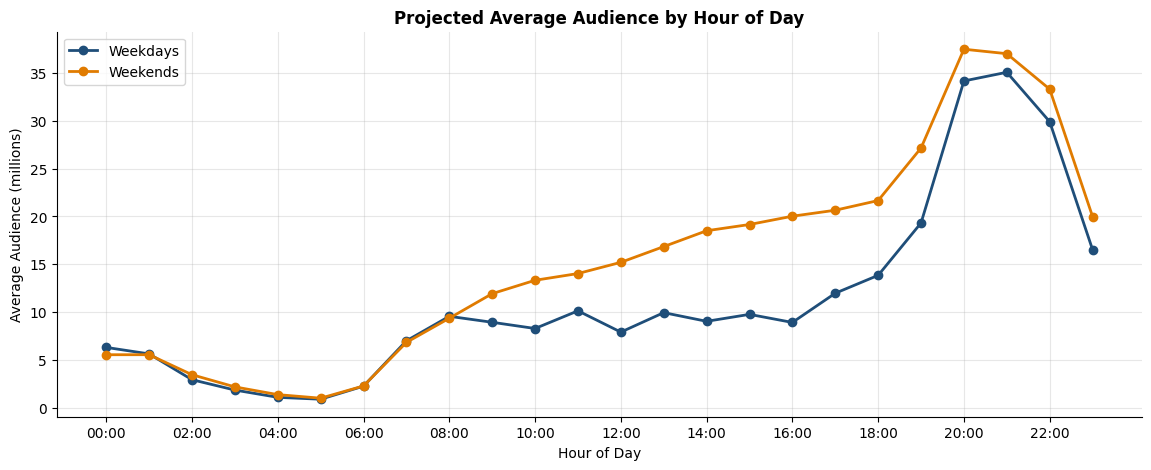

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [50]:
all_dates = pd.Series(weights_p['broadcast_date'].unique())
is_weekend = pd.to_datetime(all_dates).dt.dayofweek >= 5
num_weekdays = (~is_weekend).sum()
num_weekends = is_weekend.sum()

viewings_p['is_weekend'] = pd.to_datetime(viewings_p['broadcast_date']).dt.dayofweek >= 5

aud_weekday = {}
aud_weekend = {}

for hour in range(24):
    hour_start = pd.to_datetime(viewings_p['start_ts'].dt.date) + pd.Timedelta(hours=hour)
    hour_end = hour_start + pd.Timedelta(hours=1)

    overlap_start = viewings_p['start_ts'].clip(lower=hour_start)
    overlap_end = viewings_p['end_ts'].clip(upper=hour_end)
    overlap_sec = (overlap_end - overlap_start).dt.total_seconds()

    valid_overlap = overlap_sec > 0

    if valid_overlap.any():
        weighted_minutes = (overlap_sec[valid_overlap] / 60) * viewings_p.loc[valid_overlap, 'weight']

        w_mask = viewings_p.loc[valid_overlap, 'is_weekend']

        aud_weekday[hour] = (weighted_minutes[~w_mask].sum() / 60 / num_weekdays) / 1e6
        aud_weekend[hour] = (weighted_minutes[w_mask].sum() / 60 / num_weekends) / 1e6
    else:
        aud_weekday[hour] = 0
        aud_weekend[hour] = 0

# plot: projected average audience(M) by clockhour, weekday vs weekend
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(range(24), [aud_weekday.get(h, 0) for h in range(24)],
        label='Weekdays', color='#1f4e79', linewidth=2, marker='o', markersize=6)

ax.plot(range(24), [aud_weekend.get(h, 0) for h in range(24)],
        label='Weekends', color='#e07b00', linewidth=2, marker='o', markersize=6)

ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 2)])

ax.set_title('Projected Average Audience by Hour of Day', fontsize=12, fontweight='bold')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Average Audience (millions)')
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend()

plt.show()

peak_wd = max(aud_weekday, key=aud_weekday.get)
peak_we = max(aud_weekend, key=aud_weekend.get)

print(f"Peak hour, weekdays: {peak_wd}")
print(f"Peak hour, weekends: {peak_we}")

**Answer:** how the weekend differs.

The peak is at 21:00 on weekdays and at 20:00 on weekends. On weekends the daytime audience is much higher and spread evenly through the afternoon, while on weekdays viewing is low during working hours and concentrates sharply in the evening.

## Task 1.3 — Session length

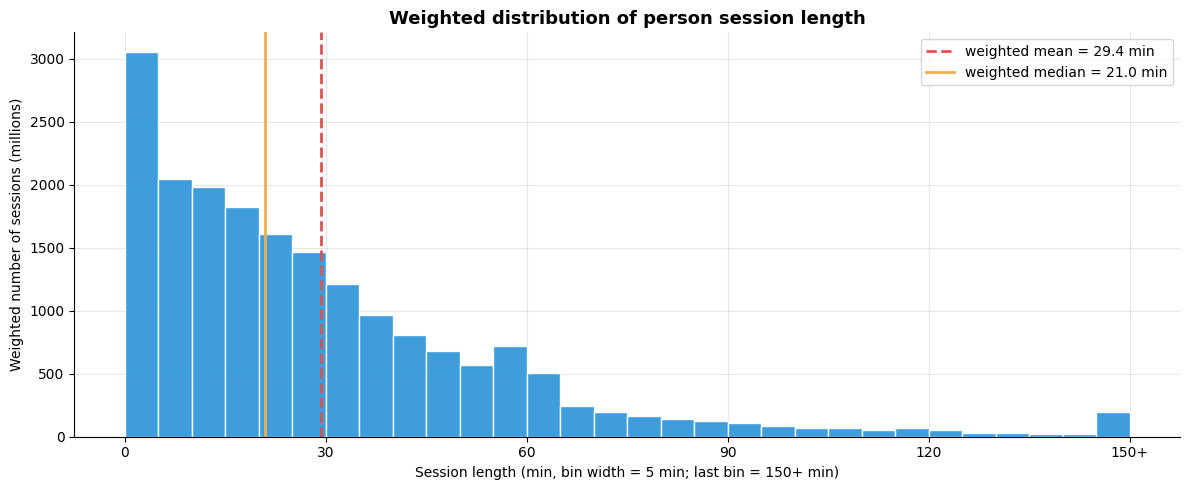

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [51]:
sess = viewings_p[['start_ts', 'end_ts', 'weight']].copy()
sess['duration_min'] = (sess['end_ts'] - sess['start_ts']).dt.total_seconds() / 60
sess = sess[(sess['duration_min'] > 0) & sess['weight'].notna()]

d = sess['duration_min'].to_numpy()
w = sess['weight'].to_numpy(dtype=float)

def weighted_mean(values, weights):
    return np.sum(values * weights) / np.sum(weights)

def weighted_quantile(values, weights, q):
    order = np.argsort(values)
    v, ww = values[order], weights[order]
    cum = np.cumsum(ww) / ww.sum()
    return v[np.searchsorted(cum, q)]

w_mean = weighted_mean(d, w)
w_median = weighted_quantile(d, w, 0.5)

BIN_WIDTH = 5
CAP = 150
bins = np.arange(0, CAP + BIN_WIDTH, BIN_WIDTH)
d_plot = np.minimum(d, CAP - 1e-6)

# plot: weighted distribution of person session length
fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(d_plot, bins=bins, weights=w / 1e6, color='#3498db',
        edgecolor='white', alpha=0.95)
ax.axvline(w_mean, color='#d9534f', linestyle='--', linewidth=2,
           label=f'weighted mean = {w_mean:.1f} min')
ax.axvline(w_median, color='#f0ad4e', linestyle='-', linewidth=2,
           label=f'weighted median = {w_median:.1f} min')

ax.set_title('Weighted distribution of person session length',
             fontsize=13, fontweight='bold')
ax.set_xlabel(f'Session length (min, bin width = {BIN_WIDTH} min; last bin = {CAP}+ min)')
ax.set_ylabel('Weighted number of sessions (millions)')


xticks_pos = list(range(0, CAP + 1, 30))
xtick_labels = [str(t) for t in range(0, CAP - 30 + 1, 30)] + [f'{CAP}+']

ax.set_xticks(range(0, CAP + BIN_WIDTH, 30))

ax.set_xticks(xticks_pos)
ax.set_xticklabels(xtick_labels)

ax.grid(alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=True)

plt.tight_layout()
plt.show()

print("Session length, weighted mean (min):", round(w_mean, 1))
print("Session length, weighted median (min):", round(w_median, 1))

**Answer:** whymean andmedian differ; which oneyouwould show aclient.

The distribution is strongly right-skewed: most sessions are short (channel surfing, a few minutes of a news segment), while a small number of very long sessions stretch the tail. The mean is pulled up by these long sessions, so it is larger than the median, which shows the length of a typical session. For a client deck I would show the median together with the distribution, because it describes a typical viewer and is not distorted by outliers. The mean alone would overstate how long people usually watch.

## Task 2 — Program reach curve

         broadcast_date  hh_rating_pct  p2_rating_pct  audience_M
telecast                                                         
1            2024-10-01            3.5            1.7        5.28
2            2024-10-02            3.1            1.5        4.68
3            2024-10-03            3.0            1.5        4.68
4            2024-10-04            3.0            1.5        4.81
5            2024-10-07            3.1            1.5        4.83
6            2024-10-08            3.2            1.6        4.97
7            2024-10-09            3.0            1.5        4.70
8            2024-10-10            3.4            1.6        5.13
9            2024-10-11            3.1            1.5        4.69
10           2024-10-14            2.9            1.4        4.59
11           2024-10-15            3.1            1.5        4.82
12           2024-10-16            3.0            1.5        4.62
13           2024-10-17            3.4            1.7        5.30
14        

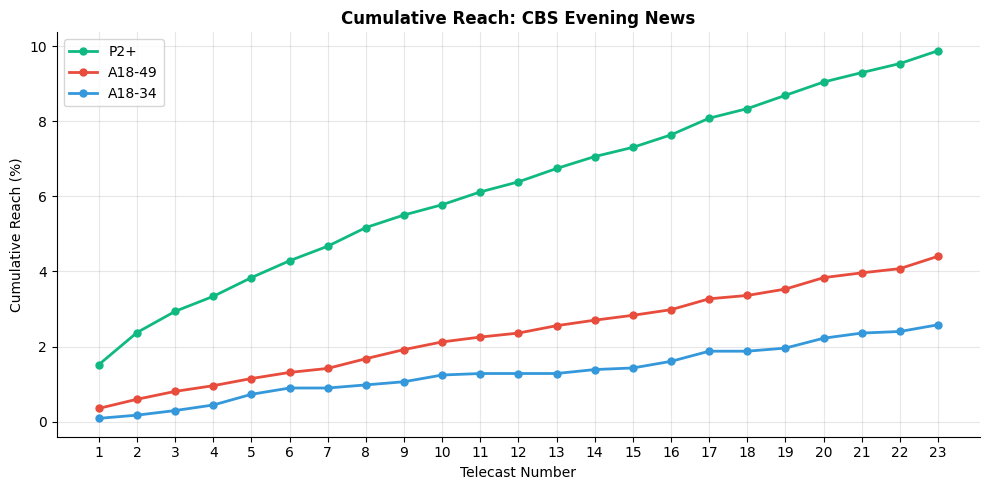

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [52]:
cbs_news_progs = programs[(programs['program_name'] == 'CBS Evening News') &
                          (programs['network_code'] == 'CBS')].copy()
cbs_news_progs['is_weekday'] = pd.to_datetime(cbs_news_progs['broadcast_date']).dt.dayofweek < 5
cbs_news_progs = cbs_news_progs[cbs_news_progs['is_weekday']].sort_values('start_ts')

age_df = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})
sex_df = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])][['respondent_id', 'attr_id']].rename(columns={'attr_id': 'sex'})
person_demos = age_df.merge(sex_df, on='respondent_id', how='outer')

def is_target(df, target):
    if target == 'P2+':
        return df['age'] >= 2
    elif target == 'A18-34':
        return (df['age'] >= 18) & (df['age'] <= 34)
    elif target == 'A18-49':
        return (df['age'] >= 18) & (df['age'] <= 49)
    return pd.Series(True, index=df.index)

targets = ['P2+', 'A18-34', 'A18-49']

avg_weights = weights_p.groupby('respondent_id')['weight'].mean().reset_index()
avg_weights = avg_weights.merge(person_demos, on='respondent_id', how='left')

univ_reach = {tgt: avg_weights[is_target(avg_weights, tgt)]['weight'].sum() for tgt in targets}

prog_viewings = viewings[viewings['network_code'] == 'CBS'].copy()

rows = []
reach_sets = {tgt: set() for tgt in targets}
reach_history = {tgt: [] for tgt in targets}

for _, row in cbs_news_progs.iterrows():
    b_date = row['broadcast_date']
    p_start = row['start_ts']
    p_end = row['end_ts']

    v_overlap = prog_viewings[(prog_viewings['start_ts'] < p_end) & (prog_viewings['end_ts'] > p_start)].copy()
    overlap_start = v_overlap['start_ts'].clip(lower=p_start)
    overlap_end = v_overlap['end_ts'].clip(upper=p_end)
    v_overlap['overlap_min'] = (overlap_end - overlap_start).dt.total_seconds() / 60
    v_valid = v_overlap[v_overlap['overlap_min'] >= 1.0]

    hh_watchers = v_valid[v_valid['resp_type'] == 'H']['respondent_id'].unique()
    day_hh = weights_hh[weights_hh['broadcast_date'] == b_date]
    hh_rating = day_hh[day_hh['respondent_id'].isin(hh_watchers)]['weight'].sum() / day_hh['weight'].sum() * 100

    p_watchers = v_valid[v_valid['resp_type'].isin(['R', 'L'])]['respondent_id'].unique()
    day_p = weights_p[weights_p['broadcast_date'] == b_date].merge(person_demos, on='respondent_id', how='left')
    day_p2 = day_p[is_target(day_p, 'P2+')]
    p_w_sum = day_p2[day_p2['respondent_id'].isin(p_watchers)]['weight'].sum()
    p2_rating = p_w_sum / day_p2['weight'].sum() * 100

    rows.append((b_date, hh_rating, p2_rating, p_w_sum / 1e6))

    w_demos = pd.DataFrame({'respondent_id': p_watchers}).merge(person_demos, on='respondent_id', how='left')
    for tgt in targets:
        reach_sets[tgt].update(w_demos[is_target(w_demos, tgt)]['respondent_id'])
        reached = avg_weights[avg_weights['respondent_id'].isin(reach_sets[tgt])]['weight'].sum()
        reach_history[tgt].append(reached / univ_reach[tgt] * 100)

rating_table = pd.DataFrame(rows, columns=['broadcast_date', 'hh_rating_pct', 'p2_rating_pct', 'audience_M'])
rating_table.index = range(1, len(rating_table) + 1)
rating_table.index.name = 'telecast'

# table: household rating, P2+ rating, projected audience (M) per telecast
print(rating_table.round({'hh_rating_pct': 1, 'p2_rating_pct': 1, 'audience_M': 2}).to_string())

# plot: cumulative reach P2+, A18-34, A18-49
fig, ax = plt.subplots(figsize=(10, 5))
x_vals = range(1, len(cbs_news_progs) + 1)
ax.plot(x_vals, reach_history['P2+'], color='#10B981', linewidth=2, marker='o', markersize=5, label='P2+')
ax.plot(x_vals, reach_history['A18-49'], color='#e74c3c', linewidth=2, marker='o', markersize=5, label='A18-49')
ax.plot(x_vals, reach_history['A18-34'], color='#3498db', linewidth=2, marker='o', markersize=5, label='A18-34')
ax.set_xticks(x_vals)
ax.set_title('Cumulative Reach: CBS Evening News', fontsize=12, fontweight='bold')
ax.set_xlabel('Telecast Number')
ax.set_ylabel('Cumulative Reach (%)')
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend()
plt.tight_layout()
plt.show()

print("Telecasts of the program:", len(cbs_news_progs))
print("Average household rating (%):", round(rating_table['hh_rating_pct'].mean(), 1))
print("Average P2+ rating (%):", round(rating_table['p2_rating_pct'].mean(), 1))
print("Average projected audience (M):", round(rating_table['audience_M'].mean(), 2))
print("Final reach P2+ (%):", round(reach_history['P2+'][-1], 1))
print("Final reach A18-34 (%):", round(reach_history['A18-34'][-1], 1))
print("Final reach A18-49 (%):", round(reach_history['A18-49'][-1], 1))

**Answer:** reach vs rating; which audience is reached best, and why.

Cumulative reach keeps growing because each telecast brings in some viewers who missed the earlier ones, while the rating stays flat (about 1.6% of P2+) because it only measures how many people watch one telecast, mostly the same loyal viewers each day. By the end of the month the program reaches 9.9% of P2+, 4.4% of A18-49 and only 2.6% of A18-34. Since each percentage is relative to its own audience’s universe, the program reaches older audiences best. This matches what we know about evening news, which is watched mostly by older people

## Task 3 — Program frequency

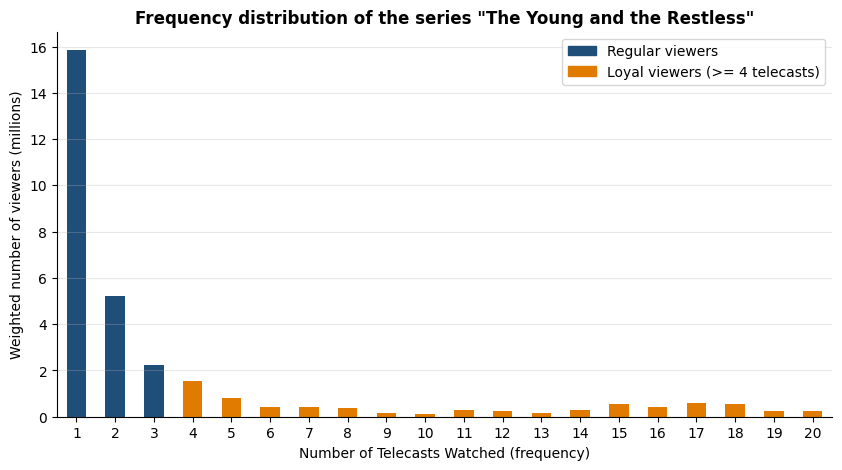

Projected viewers (M): 30.80
Average frequency (weighted): 3.6
Median frequency (weighted): 1.0
Share of views from the most loyal viewers: 0.704


In [53]:
import matplotlib.patches as mpatches

target_program = programs[programs['program_name'] == 'The Young and the Restless']
target_network = target_program['network_code'].iloc[0]

person_viewings = viewings[(viewings['resp_type'].isin(['R', 'L'])) &
                           (viewings['network_code'] == target_network)]

merged = pd.merge(person_viewings, target_program[['telecast_id', 'network_code', 'start_ts', 'end_ts']],
                  on='network_code', suffixes=('_v', '_p'))

overlap_start = merged[['start_ts_v', 'start_ts_p']].max(axis=1)
overlap_end = merged[['end_ts_v', 'end_ts_p']].min(axis=1)
overlap_duration = (overlap_end - overlap_start).dt.total_seconds()

valid_views = merged[overlap_duration >= 60]

freq_df = valid_views.groupby('respondent_id')['telecast_id'].nunique().reset_index(name='frequency')

person_weights = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]
monthly_weights = person_weights.groupby('respondent_id')['weight'].mean().reset_index(name='monthly_weight')

df_fw = pd.merge(freq_df, monthly_weights, on='respondent_id', how='inner')
df_fw['projected_views'] = df_fw['frequency'] * df_fw['monthly_weight']

projected_viewers_m = df_fw['monthly_weight'].sum() / 1e6
avg_frequency = df_fw['projected_views'].sum() / df_fw['monthly_weight'].sum()

df_fw_sorted = df_fw.sort_values('frequency')
df_fw_sorted['cum_weight'] = df_fw_sorted['monthly_weight'].cumsum()
total_weight = df_fw_sorted['monthly_weight'].sum()

median_frequency = df_fw_sorted[df_fw_sorted['cum_weight'] >= total_weight * 0.5]['frequency'].iloc[0]

p80_frequency = df_fw_sorted[df_fw_sorted['cum_weight'] >= total_weight * 0.8]['frequency'].iloc[0]

loyal_views = df_fw_sorted[df_fw_sorted['frequency'] >= p80_frequency]['projected_views'].sum()
total_views = df_fw_sorted['projected_views'].sum()
share_loyal = loyal_views / total_views

dist = df_fw_sorted.groupby('frequency')['monthly_weight'].sum() / 1e6

# plot: projected viewers (M) by number of telecasts watched
fig, ax = plt.subplots(figsize=(10, 5))

colors = ['#e07b00' if freq >= p80_frequency else '#1f4e79' for freq in dist.index]

dist.plot(kind='bar', ax=ax, color=colors)

ax.set_title('Frequency distribution of the series "The Young and the Restless"', fontsize=12, fontweight='bold')
ax.set_xlabel('Number of Telecasts Watched (frequency)')
ax.set_ylabel('Weighted number of viewers (millions)')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', linestyle='-', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

regular_patch = mpatches.Patch(color='#1f4e79', label='Regular viewers')
loyal_patch = mpatches.Patch(color='#e07b00', label=f'Loyal viewers (>= {p80_frequency} telecasts)')
ax.legend(handles=[regular_patch, loyal_patch], loc='upper right')

plt.show()

print(f"Projected viewers (M): {projected_viewers_m:.2f}")
print(f"Average frequency (weighted): {avg_frequency:.1f}")
print(f"Median frequency (weighted): {median_frequency:.1f}")
print(f"Share of views from the most loyal viewers: {share_loyal:.3f}")

**Answer:** is the average frequency a fair summary?

The most loyal viewers (identified as those who watched 4 or more telecasts) account for 0.704 (or 70.4%) of all projected views.

No, the average frequency of 3.6 is not a fair summary because the data is highly right-skewed. The vast majority of the audience—nearly 16 million out of the 30.8 million projected viewers—watched only 1 telecast. This heavy concentration at the lowest frequency is accurately reflected by the median frequency of exactly 1. However, a small core of highly loyal viewers who watched many episodes (up to 20) artificially pulls the mathematical average up to 3.6. Therefore, the median and the distribution plot provide a much more honest representation of typical viewer behavior.

## Task 4 — Networks by age and gender

In [54]:
age_attrs = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})
gender_attrs = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])][['respondent_id', 'attr_id']]
gender_attrs['gender'] = gender_attrs['attr_id'].map({201: 'M', 202: 'W'})

demo = pd.merge(age_attrs, gender_attrs[['respondent_id', 'gender']], on='respondent_id', how='inner')

def get_demo_group(row):
    g = row['gender']
    a = row['age']
    if 18 <= a <= 34: return f'{g}18-34'
    elif 35 <= a <= 54: return f'{g}35-54'
    elif a >= 55: return f'{g}55+'
    return 'Other'

demo['demo_group'] = demo.apply(get_demo_group, axis=1)
demo = demo[demo['demo_group'] != 'Other']

valid_views = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
valid_views['duration_min'] = (valid_views['end_ts'] - valid_views['start_ts']).dt.total_seconds() / 60

df_views = pd.merge(valid_views, demo[['respondent_id', 'demo_group']], on='respondent_id', how='inner')

df_views['projected_minutes'] = df_views['duration_min'] * df_views['weight']
df_views['raw_minutes'] = df_views['duration_min']

demo_groups = ['M18-34', 'W18-34', 'M35-54', 'W35-54', 'M55+', 'W55+']

# six top-5 tables (projected minutes): M18-34, W18-34, M35-54, W35-54, M55+, W55+
print("--- Top 5 Networks by Audience (Projected Minutes in Millions) ---")
for group in demo_groups:
    group_data = df_views[df_views['demo_group'] == group]
    top_5 = group_data.groupby('network_code')['projected_minutes'].sum().nlargest(5) / 1e6
    print(f"\n{group}:")
    print(top_5.round(2).to_frame())

--- Top 5 Networks by Audience (Projected Minutes in Millions) ---

M18-34:
              projected_minutes
network_code                   
FOX                     4386.65
NBC                     3910.39
CBS                     3044.35
ABC                     3010.78
FX                      1473.96

W18-34:
              projected_minutes
network_code                   
FOX                     4574.44
NBC                     4527.59
ABC                     3504.86
CBS                     2811.22
FX                      1383.47

M35-54:
              projected_minutes
network_code                   
FOX                    12804.67
NBC                    10986.68
ABC                     9037.00
CBS                     8134.07
FX                      2370.80

W35-54:
              projected_minutes
network_code                   
NBC                    11639.10
FOX                    11161.39
ABC                     9438.56
CBS                     8162.80
HGTV                    3051.81



In [55]:
valid_views['raw_minutes'] = valid_views['duration_min']
valid_views['projected_minutes'] = valid_views['duration_min'] * valid_views['weight']

net_totals = valid_views.groupby('network_code')[['projected_minutes', 'raw_minutes']].sum()

young_views = df_views[df_views['demo_group'].isin(['M18-34', 'W18-34'])]
net_young = young_views.groupby('network_code')[['projected_minutes', 'raw_minutes']].sum()

net_stats = pd.DataFrame(index=net_totals.index)
net_stats['weighted'] = (net_young['projected_minutes'] / net_totals['projected_minutes']).fillna(0)
net_stats['raw'] = (net_young['raw_minutes'] / net_totals['raw_minutes']).fillna(0)

net_stats['weighted - raw'] = net_stats['weighted'] - net_stats['raw']

net_stats_sorted = net_stats.sort_values(by='weighted', ascending=False)

youngest_net = net_stats_sorted['weighted'].idxmax()
oldest_net = net_stats_sorted['weighted'].idxmin()

# table: 18-34 share of minutes per network, weighted and raw
print("---- 18-34 Share per Network ----\n")
print(net_stats_sorted.round(3).to_string())

print(f"Youngest network: {youngest_net}")
print(f"Oldest network: {oldest_net}")

---- 18-34 Share per Network ----

              weighted    raw  weighted - raw
network_code                                 
FX               0.266  0.232           0.034
BRAVO            0.148  0.127           0.021
FOX              0.082  0.075           0.007
FOOD             0.078  0.071           0.007
NBC              0.073  0.068           0.005
ABC              0.064  0.060           0.004
HGTV             0.058  0.052           0.006
CBS              0.051  0.050           0.002
HIST             0.048  0.044           0.004
FNC              0.018  0.017           0.001
Youngest network: FX
Oldest network: FNC


**Answer:** weighted vs raw.

Weighted and raw 18–34 shares point the same way, but the weighted share is higher for almost every network (FX 0.266 vs 0.232, BRAVO 0.148 vs 0.127; broadcast networks like CBS and ABC are essentially unchanged). The weights explain this. Each panel member carries a weight, the number of Americans they represent, and that number depends on how many people like them the panel contains. The weighted figures in the table are higher than the raw ones, so 18–34 viewers have larger average weights than older viewers. In other words, young adults are under-represented in the panel relative to their share of the US population, and older people are over-represented. A raw count therefore gives older viewers too much influence and young viewers too little. The gap is largest on FX and BRAVO, where young viewers matter most.



Reporting raw panel numbers to a client would go wrong in two ways. First, raw minutes describe about 10,000 panel members, not the 317 million Americans the client is buying. Second, the raw age mix is skewed old, so every network would look older than it is. The young audience of FX, BRAVO and FOX would be understated, and an advertiser targeting 18–34 would undervalue them. Weighting is what turns a convenient but unrepresentative sample into an estimate of the whole country.

**Bonus answer:** the sales pitch.

Fox News is a cheap “pebble” with a very old audience (only ~2% of minutes from 18-34), so I would not sell it as the base of a young-adult plan, which should be built from younger pebbles like FX and BRAVO plus selective “rocks” like FOX and NBC. I would pitch it only as a low-CPM filler layer that adds a little non-duplicated young-adult reach, and fill the remaining gaps with targeted CTV “sand”.